In [110]:
import numpy as np
import pandas as pd
from scipy import stats
import hashlib
import seaborn as sns
import matplotlib.pyplot as plt

SEED = 1
SALT = 'campaign-8'


# синтетический A/B тест

Для теста берется группа клиентов участвующих в акции,  
для контрольной группы берутся те же клиенты до начала акции  
оба набора сопоставляются как будто для одной группы клиентов включили акцию, а для другой нет  

группа A - пользователи которые участвуют в акции 8 за 49 дней до ее проведения  
группа B - пользователи участвующие в акции 8, которая длится 49 дней

главный показатель - среднее количество акционных товаров, продаваемых в день за выбранный промежуток времени

Нулевая гипотеза H0:  акция ничего не меняет продажи не зависят от наличия акции  
Альтернативная гипотеза H1: изменение не равно нулю

In [19]:
td = pd.read_csv(r'../datasets/transaction_data.csv')
campaign_desc = pd.read_csv(r'../datasets/campaign_desc.csv')
campaign_table = pd.read_csv(r'../datasets/campaign_table.csv')
coupon = pd.read_csv(r'../datasets/coupon.csv')


выбор номера компании:  

In [38]:
i_comp = 8


выделение пользователей, участвующих в нужной акционной компани:  


In [63]:
mask = campaign_table['CAMPAIGN'] == i_comp
comp_users = campaign_table['household_key'][mask].tolist()
print('количество участников акции:', len(comp_users))

количество участников акции: 1076


выделение товаров участвующих в акции:  


In [62]:
p_mask = coupon['CAMPAIGN'] == i_comp
comp_products = coupon['PRODUCT_ID'][p_mask].unique().tolist()
print('количество акционных товаров:', len(comp_products))

количество акционных товаров: 17178


вывод временных параметров акции: дня старта акции, дня окончания, продолжительности акции:   

In [64]:
c_mask = campaign_desc['CAMPAIGN'] == i_comp
d_start = campaign_desc['START_DAY'][c_mask].values[0]
d_end = campaign_desc['END_DAY'][c_mask].values[0]
n_days = (d_end - d_start) + 1

кампания 8  
начинается с 412 дня, заканчивается после 460 дня  
длительность акции составляет 49 дней  

ниже сначали считается сумма количества всех акционных товаров в одном чеке    
затем ищется среднее количество проданных акционных товаров на чек за день  

In [100]:
cond_1 = td['DAY'] >= d_start - n_days
cond_2 = td['DAY'] <= d_start - 1

control = td[cond_1 & cond_2].copy()
control = control[control['household_key'].isin(comp_users)].copy()
control = control[control['PRODUCT_ID'].isin(comp_products)].copy()
control_s = control.copy()
control = control.groupby(['DAY', 'BASKET_ID'], as_index=False)['QUANTITY'].sum()
control = control.groupby(['DAY'], as_index=False)['QUANTITY'].mean()

cond_3 = td['DAY'] >= d_start
cond_4 = td['DAY'] <= d_end

treatment = td[cond_3 & cond_4].copy()
treatment = treatment[treatment['household_key'].isin(comp_users)].copy()
treatment = treatment[treatment['PRODUCT_ID'].isin(comp_products)].copy()
treatment_s = treatment.copy()
treatment = treatment.groupby(['DAY', 'BASKET_ID'], as_index=False)['QUANTITY'].sum()
treatment = treatment.groupby(['DAY'], as_index=False)['QUANTITY'].mean()

если считать что наблюдение делалось параллельно для одиноковых групп, то :

In [94]:
print('количество пользователей группы A совершавших покупки:', len(control_s['household_key'].unique()))
print('количество пользователей группы A не делавших покупок:', len(comp_users) - len(control_s['household_key'].unique()))
print('количество уникальных товаров купленных группой A:', len(control_s['PRODUCT_ID'].unique()))
print('\n')
print('количество пользователей группы B совершавших покупки:', len(treatment_s['household_key'].unique()))
print('количество пользователей группы B не делавших покупок:', len(comp_users) - len(treatment_s['household_key'].unique()))
print('количество уникальных товаров купленных группой B:', len(treatment_s['PRODUCT_ID'].unique()))

количество пользователей группы A совершавших покупки: 1047
количество пользователей группы A не делавших покупок: 29
количество уникальных товаров купленных группой A: 5509


количество пользователей группы B совершавших покупки: 1033
количество пользователей группы B не делавших покупок: 43
количество уникальных товаров купленных группой B: 5583


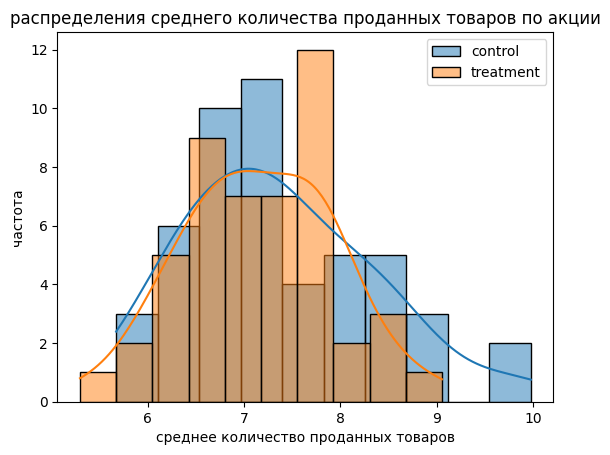

In [ ]:
sns.histplot(control['QUANTITY'], bins=10, kde=True, label='control')
sns.histplot(treatment['QUANTITY'], bins=10, kde=True, label='treatment')

plt.legend()
plt.xlabel('среднее количество проданных товаров')
plt.ylabel('частота')
plt.title('распределения среднего количества проданных товаров по акции')
plt.show()

t-test

In [107]:
ALPHA = 0.05

t_stat, p_value = stats.ttest_ind(treatment['QUANTITY'], control['QUANTITY'], alternative='two-sided')
print('t-статистика:', t_stat)
print('p-value:', p_value)

t-статистика: -1.1295269436512403
p-value: 0.2614900682170781


p-value > 0.05 значит мы не можем отвергнуть нулевую гипотезу (различий в группе не достаточно, чтобы говорить о значимом отличии групп)

Ранговая проверка Манна—Уитни

In [123]:
a = stats.mannwhitneyu(treatment['QUANTITY'], control['QUANTITY'], alternative='two-sided', method='asymptotic', use_continuity=True)
 
print('статистика:', a.statistic)
print('p-value:', a.pvalue)

статистика: 1082.0
p-value: 0.4017977617830075


аналогичныый вывод и для теста Манна-Уитни, принимаем нулевую гипотезу